In [1]:
!pip install -q optuna catboost==1.2.8

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn import set_config
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, OneHotEncoder, StandardScaler
import os
from tqdm import tqdm

from catboost import CatBoostRegressor, cv, Pool
import shap

import xgboost
from xgboost import DMatrix, XGBRegressor
from xgboost.callback import TrainingCallback

from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score, KFold

import optuna

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option('future.no_silent_downcasting', True)
set_config(transform_output="pandas")

# Load Data

In [2]:
train = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv", index_col="Id")
test = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv", index_col="Id")

MSSubClass_map = {
    20:	"1-STORY 1946 & NEWER ALL STYLES",
    30:	"1-STORY 1945 & OLDER",
    40:	"1-STORY W/FINISHED ATTIC ALL AGES",
    45:	"1-1/2 STORY - UNFINISHED ALL AGES",
    50:	"1-1/2 STORY FINISHED ALL AGES",
    60:	"2-STORY 1946 & NEWER",
    70:	"2-STORY 1945 & OLDER",
    75:	"2-1/2 STORY ALL AGES",
    80:	"SPLIT OR MULTI-LEVEL",
    85:	"SPLIT FOYER",
    90:	"DUPLEX - ALL STYLES AND AGES",
    120: "1-STORY PUD (Planned Unit Development) - 1946 & NEWER",
    150: "1-1/2 STORY PUD - ALL AGES",
    160: "2-STORY PUD - 1946 & NEWER",
    180: "PUD - MULTILEVEL - INCL SPLIT LEV/FOYER",
    190: "2 FAMILY CONVERSION - ALL STYLES AND AGES"
}

# Quite baffling what happens here. If I leave MSSubClass numerical and don't drop neither MSSubClass nor HouseStyle,
# CV score is the highest (0.8831) and dropping one of them drops by 0.3 points the CV score.
# If I convert MSSubClass to categorical and don't drop neither MSSubClass nor HouseStyle, CV score drops by 0.3 points
# from that of both numerical. If I drop HouseStyle, CV score increses (0.8828). Therefore, leaving MSSubClass may contain
# some valuable information or it's just randomness
train["MSSubClass"] = train["MSSubClass"].map(MSSubClass_map)
test["MSSubClass"] = test["MSSubClass"].map(MSSubClass_map)

outliers_mask = (train["GrLivArea"] > 4600) | (train["LotFrontage"] > 300)
X = train.drop("SalePrice", axis=1)[~outliers_mask].copy()
y = train["SalePrice"][~outliers_mask].copy()

 ## Custom Classes

In [3]:
from sklearn.base import BaseEstimator, TransformerMixin

class LotFrontageImputer(BaseEstimator, TransformerMixin):
    def __init(self):
        pass
        
    def fit(self, X, y=None):
        self.means_ = X.groupby(["Neighborhood"])["LotFrontage"].mean()
        self.global_mean_ = X["LotFrontage"].mean()
        return self

    def transform(self, X):
        x = X.copy()
        neighborhood_means = x["Neighborhood"].map(self.means_)
        neighborhood_means = neighborhood_means.fillna(self.global_mean_)
        x["LotFrontage"] = x["LotFrontage"].fillna(neighborhood_means)
        return x

class OtherImputer(BaseEstimator, TransformerMixin):
    def __init__(self, threshold: int=5):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X) if isinstance(X, pd.Series) else X
        self.rare_categories_ = {}
        self.frequent_categories_ = {}
        for feature in X.columns:
            temp = X[feature].value_counts()
            
            categories_under_threshold = temp[temp < self.threshold].index.tolist()
            self.rare_categories_[feature] = categories_under_threshold

            categories_above_threshold = temp[temp >= self.threshold].index.tolist()
            self.frequent_categories_[feature] = categories_above_threshold
            
        return self
    
    def transform(self, X):
        x = pd.DataFrame(X) if isinstance(X, pd.Series) else X.copy()
        for feature, frequent_categories in self.frequent_categories_.items():
            mask = ~x[feature].isin(frequent_categories) & x[feature].notna()
            x.loc[mask, feature] = "Other"
        return x

# CatBoost

In [4]:
def handle_null_values(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    # From the data_description.txt file, NaNs mean absence of
    x["PoolQC"] = x["PoolQC"].replace(np.nan, "No Pool")
    x["MiscFeature"] = x["MiscFeature"].replace(np.nan, "No Miscellaneous") # There are 2 values with MiscFeature not NaN and MiscValue = 0. We assume those Features don't add value
    x["Alley"] = x["Alley"].replace(np.nan, "No Alley Access")
    x["Fence"] = x["Fence"].replace(np.nan, "No Fence")
    x["FireplaceQu"] = x["FireplaceQu"].replace(np.nan, "No Fireplace")
    garage_mask = (x["GarageType"].isna()) & (x["GarageYrBlt"].isna()) & (x["GarageFinish"].isna()) & (x["GarageQual"].isna()) & (x["GarageCond"].isna())
    x.loc[garage_mask, ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]] = "No Garage"
    x.loc[garage_mask, "GarageYrBlt"] = -1
    
    # NaNs not in data_description.txt file
    x.loc[x["MasVnrArea"] < 5, "MasVnrArea"] = 0 
    masvnr_mask = (x["MasVnrType"].isna()) & (x["MasVnrArea"].fillna(0) == 0) # np.nan == np.nan yields False, so we can't use .isin([0, np.nan])
    x.loc[masvnr_mask, "MasVnrType"] = "No Masonry"
    x.loc[masvnr_mask, "MasVnrArea"] = 0
    masvnr_mask = (x["MasVnrArea"].between(280, 1000)) & (x["MasVnrType"].isna())
    x.loc[masvnr_mask, "MasVnrType"] = "BrkFace" # Stone is more expensive than BrkFace, and NaNs in MasVnrType when MasVnrArea is high are more likely to be BrkFace, though enconding it as Stone yields a rise of 0.0005 on R2, which might be due to noise

    bsmt_mask = (x["BsmtFinType1"].isna()) & (x["BsmtFinType2"].isna()) & (x["BsmtExposure"].isna()) & (x["BsmtCond"].isna()) & (x["BsmtQual"].isna())
    x.loc[bsmt_mask, ["BsmtFinType1", "BsmtFinType2", "BsmtExposure", "BsmtCond", "BsmtQual"]] = "No Basement"
    x.loc[bsmt_mask, ["BsmtFullBath", "BsmtHalfBath", "BsmtFinSF1",	"BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF"]] = 0
    x["BsmtHalfBath"] = x["BsmtHalfBath"].astype(int)
    x["BsmtFullBath"] = x["BsmtFullBath"].astype(int)

    x["Electrical"] = x["Electrical"].fillna("SBrkr")
    x["Functional"] = x["Functional"].fillna("Typ")
    x.loc[(x["MSZoning"].isna()) & (x["Neighborhood"] == "IDOTRR"), "MSZoning"] = "RM"
    x.loc[(x["MSZoning"].isna()) & (x["Neighborhood"] == "Mitchel"), "MSZoning"] = "RL"
    x["SaleType"] = x["SaleType"].fillna("WD")
    x["BsmtCond"] = x["BsmtCond"].fillna("TA")
    x["GarageQual"] = x["GarageQual"].fillna("TA")
    x["GarageCond"] = x["GarageCond"].fillna("TA")
    x["Utilities"] = x["Utilities"].fillna("AllPub")
    
    return x

def feature_engineering(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    x["IsLotFrontageNull"] = x["LotFrontage"].isna()
    x["YearRemodAddGap"] = x["YearRemodAdd"] - x["YearBuilt"]
    x["YearSoldGap"] = x["YrSold"] - x["YearRemodAdd"]
    x["GarageRatio"] = np.where(
        x["GarageArea"] != 0,
        x["GarageArea"] / x["GarageCars"],
        0
    )
    x["3SsnPorch"] = x["3SsnPorch"] != 0
    x["KitchenAbvGr"] = x["KitchenAbvGr"].clip(lower=1)
    x["MoSold"] = np.sin(1/6 * np.pi * x["MoSold"])

    return x
    
def drop_features(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    drop_vars = [
        "MiscVal", # Stands for Miscellaneous Features Value. Very skewed distribution towards 0, maybe consider converting it to a flag or train only with MiscFeatures
        "Utilities", # On the training set, there is only one sample not in the main category
        "PoolQC", "PoolArea", # Very skewed distributions, and using a flag HasPool didn't improve the performance
        "Exterior2nd", # Highly correlated to Exterior1st (Cramér's V and MI of ~0.8). We saw an improvement in performance
        # "GarageQual", # Highly correlated to GarageCond (Cramér's V and MI of ~0.7). We saw an improvement in performance
        "HouseStyle", # Highly correlated to MSSubClass (MSSubClass contains HouseStyle information), though dropping it decreased the cv score
        "YrSold", "YearBuilt", # We drop them because we created Year Gaps that I think represent better the reality. I experienced a drop of 0.0002 in R2, but it might be due to noise
        "GarageArea",
        #"BsmtUnfSF",
    ]
    x = x.drop(columns=drop_vars)

    return x

# Including MSSubClass here drops the CV score a lot
nominal_cat_vars = ['Alley', 'BldgType', 'CentralAir', 'Condition1', 'Condition2', 'Electrical', 'Exterior1st',
                    'Exterior2nd', 'Foundation', 'Functional', 'GarageFinish', 'GarageType', 'Heating',
                    'HouseStyle', 'LandContour', 'LandSlope', 'LotConfig', 'LotShape', 'MSZoning', 'MasVnrType',
                    'MiscFeature', 'Neighborhood', 'PavedDrive', 'RoofMatl', 'RoofStyle', 'SaleCondition',
                    'SaleType', 'Street', 'Utilities']

ordinal_cat_vars = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
                    'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence']
ordinal_cat_vars_order = []
for var in ordinal_cat_vars:
    if var in ("BsmtCond", "BsmtQual"):
        ordinal_cat_vars_order.append(["No Basement", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "BsmtExposure":
        ordinal_cat_vars_order.append(["No Basement", "No", "Mn", "Av", "Gd"])
    elif var in ("BsmtFinType1", "BsmtFinType2"):
        ordinal_cat_vars_order.append(["No Basement", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"])
    elif var == "FireplaceQu":
        ordinal_cat_vars_order.append(["No Fireplace", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var in ("GarageQual", "GarageCond"):
        ordinal_cat_vars_order.append(["No Garage", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "PoolQC":
        ordinal_cat_vars_order.append(["No Pool", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "Fence":
        ordinal_cat_vars_order.append(["No Fence", "MnWw", "GdWo", "MnPrv","GdPrv"])
    else:
        ordinal_cat_vars_order.append(["Po", "Fa", "TA", "Gd", "Ex"])

nominal_pipeline = Pipeline(steps=[
    ("rare_categories", OtherImputer(20))
])
ordinal_pipeline = Pipeline(steps=[
    ("ordinal_enconding", OrdinalEncoder(categories=ordinal_cat_vars_order, handle_unknown="use_encoded_value", unknown_value=np.nan))
])

cat_nans_feat = ["Functional", "MSZoning", "SaleType", "BsmtCond", "GarageQual", "GarageCond", "BsmtHalfBath"]
num_nans_feat = ["BsmtHalfBath"]

nans_to_most_frequent = ColumnTransformer(transformers=[
    ("cat_imputer", SimpleImputer(strategy="most_frequent"), cat_nans_feat),
    #("num_imputer", SimpleImputer(strategy="constant", fill_value=0), num_nans_feat)
], verbose_feature_names_out=False, remainder="passthrough")
preprocessing = ColumnTransformer(transformers=[
    ("nominal_pipeline", nominal_pipeline, nominal_cat_vars),
    ("ordinal_pipeline", ordinal_pipeline, ordinal_cat_vars),
], verbose_feature_names_out=False, remainder="passthrough")

def cat_nans(X: pd.DataFrame):
    x = X.copy()
    
    cat_vars = x.select_dtypes("object").columns
    x[cat_vars] = x[cat_vars].fillna("Missing") # Catboost requires categorical features to be non null
    x[cat_vars] = x[cat_vars].astype("category") # Catboost doesn't distinguish between category or object dtype, but XGBoost and LightGBM do

    return x
    
wf_catboost = Pipeline(steps=[
    ("handle_null_values", FunctionTransformer(handle_null_values)),
    ("nans_to_most_frequent_pipeline", nans_to_most_frequent),
    ("lotfrontage_nulls", LotFrontageImputer()),
    ("preprocessing", preprocessing),
    ("feature_engineering", FunctionTransformer(feature_engineering)),
    ("drop_features", FunctionTransformer(drop_features)),
    ("final_nans", FunctionTransformer(cat_nans))
])

X_trans = wf_catboost.fit_transform(X)
cat_vars = X_trans.select_dtypes("category").columns

pipe_catboost = Pipeline(steps=[
    ("handle_null_values", FunctionTransformer(handle_null_values)),
    ("nans_to_most_frequent_pipeline", nans_to_most_frequent),
    ("lotfrontage_nulls", LotFrontageImputer()),
    ("preprocessing", preprocessing),
    ("feature_engineering", FunctionTransformer(feature_engineering)),
    ("drop_features", FunctionTransformer(drop_features)),
    ("final_nans", FunctionTransformer(cat_nans)),
    ("catboost", CatBoostRegressor(iterations=1500, random_state=42, cat_features=cat_vars.tolist(), verbose=False))
])

In [5]:
train_pool = Pool(data=X_trans, label=y, cat_features=cat_vars.to_list())

catboost = CatBoostRegressor(iterations=1500, random_state=42, cat_features=cat_vars.tolist(), verbose=False)
# catboost.fit(train_pool)

# params = {
#     "loss_function": "RMSE",
#     "eval_metric": "RMSE",
#     "custom_metric": ["R2"],
#     "random_seed": 42,
#     "verbose": 0,
#     "task_type": "CPU",
#     "iterations": 1500,
#     "one_hot_max_size": 2
# }

# cv_scores = cv(
#     pool = train_pool,
#     params = params,
#     fold_count = 5,
#     shuffle = True,
#     partition_random_seed = 42,
#     plot = False,
#     early_stopping_rounds = None
# )

# best_iteration = cv_scores["test-RMSE-mean"].idxmin()
# print(f"Best Iteration: {best_iteration}")

# best_rmse = cv_scores["test-RMSE-mean"].iloc[best_iteration]
# best_rmse_std = cv_scores["test-RMSE-std"].iloc[best_iteration]
# best_r2 = cv_scores["test-R2-mean"].iloc[best_iteration]
# best_r2_std = cv_scores["test-R2-std"].iloc[best_iteration]

# print(f"Best Validation RMSE: {best_rmse:.4f} ± {best_rmse_std:.4f}")
# print(f"Best Validation R²:   {best_r2:.4f} + ± {best_r2_std:.4f}")

# Linear Regression

In [6]:
def handle_null_values(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    # From the data_description.txt file, NaNs mean absence of
    x["PoolQC"] = x["PoolQC"].replace(np.nan, "No Pool")
    x["MiscFeature"] = x["MiscFeature"].replace(np.nan, "No Miscellaneous") # There are 2 values with MiscFeature not NaN and MiscValue = 0. We assume those Features don't add value
    x["Alley"] = x["Alley"].replace(np.nan, "No Alley Access")
    x["Fence"] = x["Fence"].replace(np.nan, "No Fence")
    x["FireplaceQu"] = x["FireplaceQu"].replace(np.nan, "No Fireplace")
    garage_mask = (x["GarageType"].isna()) & (x["GarageYrBlt"].isna()) & (x["GarageFinish"].isna()) & (x["GarageQual"].isna()) & (x["GarageCond"].isna())
    x.loc[garage_mask, ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]] = "No Garage"
    x.loc[garage_mask, "GarageYrBlt"] = -1
    
    # NaNs not in data_description.txt file
    x.loc[x["MasVnrArea"] < 5, "MasVnrArea"] = 0 
    masvnr_mask = (x["MasVnrType"].isna()) & (x["MasVnrArea"].fillna(0) == 0) # np.nan == np.nan yields False, so we can't use .isin([0, np.nan])
    x.loc[masvnr_mask, "MasVnrType"] = "No Masonry"
    x.loc[masvnr_mask, "MasVnrArea"] = 0
    masvnr_mask = (x["MasVnrArea"].between(280, 1000)) & (x["MasVnrType"].isna())
    x.loc[masvnr_mask, "MasVnrType"] = "BrkFace" # Stone is more expensive than BrkFace, and NaNs in MasVnrType when MasVnrArea is high are more likely to be BrkFace, though enconding it as Stone yields a rise of 0.0005 on R2, which might be due to noise

    bsmt_mask = (x["BsmtFinType1"].isna()) & (x["BsmtFinType2"].isna()) & (x["BsmtExposure"].isna()) & (x["BsmtCond"].isna()) & (x["BsmtQual"].isna())
    x.loc[bsmt_mask, ["BsmtFinType1", "BsmtFinType2", "BsmtExposure", "BsmtCond", "BsmtQual"]] = "No Basement"
    x.loc[bsmt_mask, ["BsmtFullBath", "BsmtHalfBath", "BsmtFinSF1",	"BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF"]] = 0
    x["BsmtHalfBath"] = x["BsmtHalfBath"].astype(int)
    x["BsmtFullBath"] = x["BsmtFullBath"].astype(int)

    x["Electrical"] = x["Electrical"].fillna("SBrkr")
    x["Functional"] = x["Functional"].fillna("Typ")
    x.loc[(x["MSZoning"].isna()) & (x["Neighborhood"] == "IDOTRR"), "MSZoning"] = "RM"
    x.loc[(x["MSZoning"].isna()) & (x["Neighborhood"] == "Mitchel"), "MSZoning"] = "RL"
    x["SaleType"] = x["SaleType"].fillna("WD")
    x["BsmtCond"] = x["BsmtCond"].fillna("TA")
    x["GarageQual"] = x["GarageQual"].fillna("TA")
    x["GarageCond"] = x["GarageCond"].fillna("TA")
    x["Utilities"] = x["Utilities"].fillna("AllPub")
    
    return x

def feature_engineering(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    x["IsLotFrontageNull"] = x["LotFrontage"].isna()
    x["YearRemodAddGap"] = x["YearRemodAdd"] - x["YearBuilt"]
    x["YearSoldGap"] = x["YrSold"] - x["YearRemodAdd"]
    x["GarageRatio"] = np.where(
        x["GarageArea"] != 0,
        x["GarageArea"] / x["GarageCars"],
        0
    )
    x["BsmtUnfRatio"] = np.where(
        x["TotalBsmtSF"] != 0,
        x["BsmtUnfSF"] / x["TotalBsmtSF"],
        -1
    )
    x["TotalPorch"] = x["WoodDeckSF"] + x["OpenPorchSF"] + x["EnclosedPorch"] + x["ScreenPorch"] + x["3SsnPorch"]
    x["TotalBath"] = x["FullBath"] + 0.5*x["HalfBath"]
    x["TotalBsmtBath"] = x["BsmtFullBath"] + 0.5*x["BsmtHalfBath"]
    x["KitchenAbvGr"] = x["KitchenAbvGr"].clip(lower=1)
    x["MoSold"] = np.sin(1/6 * np.pi * x["MoSold"])
    x["HasPool"] = x["PoolArea"] != 0
    x["HasFence"] = x["Fence"] != "No Fence"

    drop_vars = ["YearBuilt", "YrSold", "MiscVal", "Utilities", "PoolQC", "PoolArea", "Exterior2nd", "HouseStyle",
                 "GarageArea", "Fence", "BsmtUnfSF", "BsmtFinType2", "GarageYrBlt", "GarageQual", "Condition2",
                "RoofMatl", "YrSold", "LandSlope", "HouseStyle", "YearRemodAdd"]
    
    return x.drop(columns=drop_vars)

# Including MSSubClass here drops the CV score a lot
nominal_cat_vars = ['Alley', 'BldgType', 'CentralAir', 'Condition1', 'Electrical', 'Exterior1st',
                    'Foundation', 'Functional', 'GarageFinish', 'GarageType', 'Heating',
                    'LandContour', 'LotConfig', 'LotShape', 'MSZoning', 'MasVnrType',
                    'MiscFeature', 'PavedDrive', 'RoofStyle', 'SaleCondition',
                    'SaleType', 'Street', 'Neighborhood', "MSSubClass"]

ordinal_cat_vars = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
                    'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageCond']
ordinal_cat_vars_order = []
for var in ordinal_cat_vars:
    if var in ("BsmtCond", "BsmtQual"):
        ordinal_cat_vars_order.append(["No Basement", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "BsmtExposure":
        ordinal_cat_vars_order.append(["No Basement", "No", "Mn", "Av", "Gd"])
    elif var in ("BsmtFinType1", "BsmtFinType2"):
        ordinal_cat_vars_order.append(["No Basement", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"])
    elif var == "FireplaceQu":
        ordinal_cat_vars_order.append(["No Fireplace", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var in ("GarageQual", "GarageCond"):
        ordinal_cat_vars_order.append(["No Garage", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "PoolQC":
        ordinal_cat_vars_order.append(["No Pool", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "Fence":
        ordinal_cat_vars_order.append(["No Fence", "MnWw", "GdWo", "MnPrv","GdPrv"])
    else:
        ordinal_cat_vars_order.append(["Po", "Fa", "TA", "Gd", "Ex"])

nominal_pipeline = Pipeline(steps=[
    ("rare_categories", OtherImputer(20)),
    ("one_hot_encoding", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])
ordinal_pipeline = Pipeline(steps=[
    ("nans_ordinal", SimpleImputer(strategy="most_frequent")),
    ("ordinal_enconding", OrdinalEncoder(categories=ordinal_cat_vars_order, handle_unknown="use_encoded_value", unknown_value=np.nan))
])

preprocessing = ColumnTransformer(transformers=[
    ("nominal_pipeline", nominal_pipeline, nominal_cat_vars),
    ("ordinal_pipeline", ordinal_pipeline, ordinal_cat_vars),
    ("nans_num", SimpleImputer(strategy="median"), make_column_selector(dtype_include=np.number)),
], verbose_feature_names_out=False, remainder="passthrough")

wf_linear = Pipeline(steps=[
    ("handle_null_values", FunctionTransformer(handle_null_values)),
    ("lotfrontage_nulls", LotFrontageImputer()),
    ("feature_engineering", FunctionTransformer(feature_engineering)),
    ("preprocessing", preprocessing),
    ])

X_trans = wf_linear.fit_transform(X)

pipe_lr = Pipeline(steps=[
    ("handle_null_values", FunctionTransformer(handle_null_values)),
    ("lotfrontage_nulls", LotFrontageImputer()),
    ("feature_engineering", FunctionTransformer(feature_engineering)),
    ("preprocessing", preprocessing),
    ("linear", LinearRegression())
    ])

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
lr = Ridge()

r2_scores = []
rmse_scores = []

rmse_score = lambda true, pred: np.sqrt(np.mean((true - pred)**2))

for train_idx, val_idx in kf.split(X_trans, y):
    X_train, X_val = X_trans.iloc[train_idx], X_trans.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    lr.fit(X_train, np.log(y_train))

    y_pred = lr.predict(X_val)

    r2_scores.append(r2_score(y_val, np.exp(y_pred)))
    rmse_scores.append(rmse_score(y_val, np.exp(y_pred)))

print(f"Val RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
print(f"Val R2: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")

Val RMSE: 20498.5934 ± 1053.2543
Val R2: 0.9323 ± 0.0063


# SVM

In [8]:
def handle_null_values(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    # From the data_description.txt file, NaNs mean absence of
    x["PoolQC"] = x["PoolQC"].replace(np.nan, "No Pool")
    x["MiscFeature"] = x["MiscFeature"].replace(np.nan, "No Miscellaneous") # There are 2 values with MiscFeature not NaN and MiscValue = 0. We assume those Features don't add value
    x["Alley"] = x["Alley"].replace(np.nan, "No Alley Access")
    x["Fence"] = x["Fence"].replace(np.nan, "No Fence")
    x["FireplaceQu"] = x["FireplaceQu"].replace(np.nan, "No Fireplace")
    garage_mask = (x["GarageType"].isna()) & (x["GarageYrBlt"].isna()) & (x["GarageFinish"].isna()) & (x["GarageQual"].isna()) & (x["GarageCond"].isna())
    x.loc[garage_mask, ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]] = "No Garage"
    x.loc[garage_mask, "GarageYrBlt"] = -1
    
    # NaNs not in data_description.txt file
    x.loc[x["MasVnrArea"] < 5, "MasVnrArea"] = 0 
    masvnr_mask = (x["MasVnrType"].isna()) & (x["MasVnrArea"].fillna(0) == 0) # np.nan == np.nan yields False, so we can't use .isin([0, np.nan])
    x.loc[masvnr_mask, "MasVnrType"] = "No Masonry"
    x.loc[masvnr_mask, "MasVnrArea"] = 0
    masvnr_mask = (x["MasVnrArea"].between(280, 1000)) & (x["MasVnrType"].isna())
    x.loc[masvnr_mask, "MasVnrType"] = "BrkFace" # Stone is more expensive than BrkFace, and NaNs in MasVnrType when MasVnrArea is high are more likely to be BrkFace, though enconding it as Stone yields a rise of 0.0005 on R2, which might be due to noise

    bsmt_mask = (x["BsmtFinType1"].isna()) & (x["BsmtFinType2"].isna()) & (x["BsmtExposure"].isna()) & (x["BsmtCond"].isna()) & (x["BsmtQual"].isna())
    x.loc[bsmt_mask, ["BsmtFinType1", "BsmtFinType2", "BsmtExposure", "BsmtCond", "BsmtQual"]] = "No Basement"
    x.loc[bsmt_mask, ["BsmtFullBath", "BsmtHalfBath", "BsmtFinSF1",	"BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF"]] = 0
    x["BsmtHalfBath"] = x["BsmtHalfBath"].astype(int)
    x["BsmtFullBath"] = x["BsmtFullBath"].astype(int)

    x["Electrical"] = x["Electrical"].fillna("SBrkr")
    x["Functional"] = x["Functional"].fillna("Typ")
    x.loc[(x["MSZoning"].isna()) & (x["Neighborhood"] == "IDOTRR"), "MSZoning"] = "RM"
    x.loc[(x["MSZoning"].isna()) & (x["Neighborhood"] == "Mitchel"), "MSZoning"] = "RL"
    x["SaleType"] = x["SaleType"].fillna("WD")
    x["BsmtCond"] = x["BsmtCond"].fillna("TA")
    x["GarageQual"] = x["GarageQual"].fillna("TA")
    x["GarageCond"] = x["GarageCond"].fillna("TA")
    x["Utilities"] = x["Utilities"].fillna("AllPub")
    
    return x

def feature_engineering(X: pd.DataFrame) -> pd.DataFrame:

    x = X.copy()
    
    x["IsLotFrontageNull"] = x["LotFrontage"].isna()
    x["YearRemodAddGap"] = x["YearRemodAdd"] - x["YearBuilt"]
    x["YearSoldGap"] = x["YrSold"] - x["YearRemodAdd"]
    x["GarageRatio"] = np.where(
        x["GarageArea"] != 0,
        x["GarageArea"] / x["GarageCars"],
        0
    )
    x["BsmtUnfRatio"] = np.where(
        x["TotalBsmtSF"] != 0,
        x["BsmtUnfSF"] / x["TotalBsmtSF"],
        -1
    )
    x["TotalPorch"] = x["WoodDeckSF"] + x["OpenPorchSF"] + x["EnclosedPorch"] + x["ScreenPorch"] + x["3SsnPorch"]
    x["TotalBath"] = x["FullBath"] + 0.5*x["HalfBath"]
    x["TotalBsmtBath"] = x["BsmtFullBath"] + 0.5*x["BsmtHalfBath"]
    x["KitchenAbvGr"] = x["KitchenAbvGr"].clip(lower=1)
    x["MoSold"] = np.sin(1/6 * np.pi * x["MoSold"])
    x["HasPool"] = x["PoolArea"] != 0
    x["HasFence"] = x["Fence"] != "No Fence"

    drop_vars = ["YearBuilt", "YrSold", "MiscVal", "Utilities", "PoolQC", "PoolArea", "Exterior2nd", "HouseStyle",
                 "GarageArea", "Fence", "BsmtUnfSF", "BsmtFinType2", "GarageYrBlt", "GarageQual", "Condition2",
                "RoofMatl", "YrSold", "LandSlope", "HouseStyle", "YearRemodAdd"]
    
    return x.drop(columns=drop_vars)

# Including MSSubClass here drops the CV score a lot
nominal_cat_vars = ['Alley', 'BldgType', 'CentralAir', 'Condition1', 'Electrical', 'Exterior1st',
                    'Foundation', 'Functional', 'GarageFinish', 'GarageType', 'Heating',
                    'LandContour', 'LotConfig', 'LotShape', 'MSZoning', 'MasVnrType',
                    'MiscFeature', 'PavedDrive', 'RoofStyle', 'SaleCondition',
                    'SaleType', 'Street', 'Neighborhood', "MSSubClass"]

ordinal_cat_vars = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
                    'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageCond']
ordinal_cat_vars_order = []
for var in ordinal_cat_vars:
    if var in ("BsmtCond", "BsmtQual"):
        ordinal_cat_vars_order.append(["No Basement", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "BsmtExposure":
        ordinal_cat_vars_order.append(["No Basement", "No", "Mn", "Av", "Gd"])
    elif var in ("BsmtFinType1", "BsmtFinType2"):
        ordinal_cat_vars_order.append(["No Basement", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"])
    elif var == "FireplaceQu":
        ordinal_cat_vars_order.append(["No Fireplace", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var in ("GarageQual", "GarageCond"):
        ordinal_cat_vars_order.append(["No Garage", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "PoolQC":
        ordinal_cat_vars_order.append(["No Pool", "Po", "Fa", "TA", "Gd", "Ex"])
    elif var == "Fence":
        ordinal_cat_vars_order.append(["No Fence", "MnWw", "GdWo", "MnPrv","GdPrv"])
    else:
        ordinal_cat_vars_order.append(["Po", "Fa", "TA", "Gd", "Ex"])

nominal_pipeline = Pipeline(steps=[
    ("rare_categories", OtherImputer(20)),
    ("one_hot_encoding", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])
ordinal_pipeline = Pipeline(steps=[
    ("nans_ordinal", SimpleImputer(strategy="most_frequent")),
    ("ordinal_enconding", OrdinalEncoder(categories=ordinal_cat_vars_order, handle_unknown="use_encoded_value", unknown_value=np.nan))
])

preprocessing = ColumnTransformer(transformers=[
    ("nominal_pipeline", nominal_pipeline, nominal_cat_vars),
    ("ordinal_pipeline", ordinal_pipeline, ordinal_cat_vars),
    ("num_pipeline", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), make_column_selector(dtype_include=np.number)),
], verbose_feature_names_out=False, remainder="passthrough")

wf_svm = Pipeline(steps=[
    ("handle_null_values", FunctionTransformer(handle_null_values)),
    ("lotfrontage_nulls", LotFrontageImputer()),
    ("feature_engineering", FunctionTransformer(feature_engineering)),
    ("preprocessing", preprocessing),
    ])

X_trans = wf_svm.fit_transform(X)
lr = SVR(epsilon=0.01, gamma="scale")

pipe_svm = Pipeline(steps=[
    ("handle_null_values", FunctionTransformer(handle_null_values)),
    ("lotfrontage_nulls", LotFrontageImputer()),
    ("feature_engineering", FunctionTransformer(feature_engineering)),
    ("preprocessing", preprocessing),
    ("linear", lr)
    ])

In [9]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_scores = []
rmse_scores = []

rmse_score = lambda true, pred: np.sqrt(np.mean((true - pred)**2))

for train_idx, val_idx in kf.split(X_trans, y):
    X_train, X_val = X_trans.iloc[train_idx], X_trans.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    
    lr.fit(X_train, np.log(y_train))

    y_pred = lr.predict(X_val)

    r2_scores.append(r2_score(y_val, np.exp(y_pred)))
    rmse_scores.append(rmse_score(y_val, np.exp(y_pred)))

print(f"Val RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
print(f"Val R2: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")

Val RMSE: 23406.0204 ± 3883.8495
Val R2: 0.9122 ± 0.0193


# Ensemble

In [10]:
from sklearn.ensemble import StackingRegressor, RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor

estimators = [
    ("catboost", pipe_catboost),
    ("svm", pipe_svm),
    ("lr", pipe_lr)
]

stck = StackingRegressor(
    estimators = estimators,
    final_estimator = LinearRegression(),
    cv = kf
)

stck.fit(X, np.log(y))
print("=")

=


# Submission

In [11]:
pred = {"SalePrice": np.exp(stck.predict(test))}

submission = pd.DataFrame(pred["SalePrice"], index=test.index)
submission.columns = ["SalePrice"]
submission.to_csv("submission.csv", index=True)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 8, 15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 8, 15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


In [12]:
yy = np.log(y)

pipe_catboost.fit(X, yy)
catboost_pred = pipe_catboost.predict(test)

pipe_lr.fit(X, yy)
lr_pred = pipe_lr.predict(test)

pipe_svm.fit(X, yy)
svm_pred = pipe_svm.predict(test)

stck_pred = stck.predict(test)

dicc = {
    "catboost": np.exp(catboost_pred),
    "svm": np.exp(svm_pred),
    "lr": np.exp(lr_pred)
}

preds_df = pd.DataFrame(dicc, index=test.index)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 8, 15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 8, 15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 8, 15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [5, 8, 15] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarnin

In [13]:
preds_df.corr()

,catboost,svm,lr
catboost,1.000000,0.980277,0.939105
svm,0.980277,1.000000,0.891723
lr,0.939105,0.891723,1.000000


In [14]:
stck.final_estimator_.coef_

array([0.43178499, 0.22194195, 0.36524704])

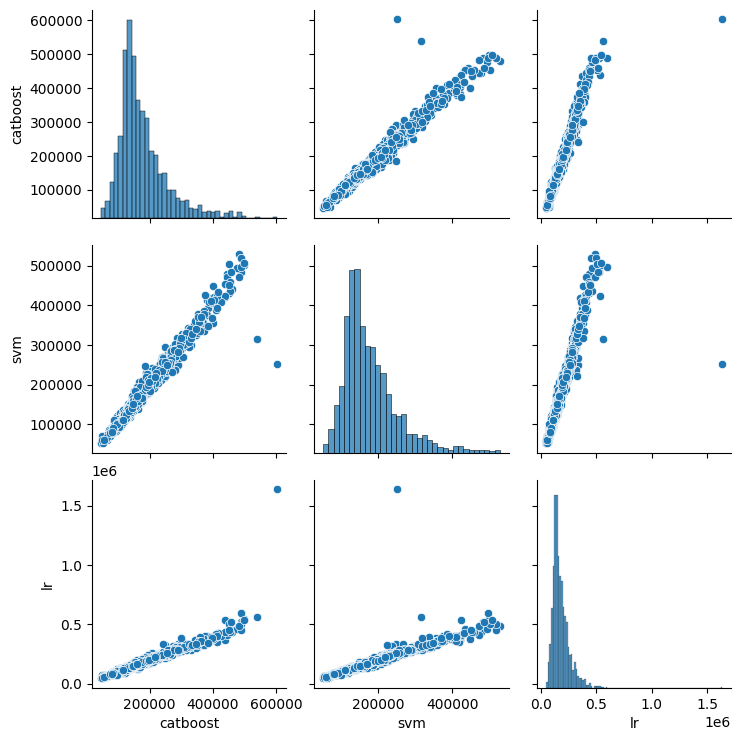

In [15]:
sns.pairplot(preds_df)